In [2]:
import polars as pl
import numpy as np
import sys
sys.path.append("..")
from src.cleaning.limpiado import limpiar_datos
from src.models.heterogeneidad import giniSimpon, iqv, entropia
from config.rutas import RUTA_DATOS_CRUDOS

df_limpio = limpiar_datos(RUTA_DATOS_CRUDOS)
print("Filas sin nulos en edad:", df_limpio.shape[0])

Filas sin nulos en edad: 24560


In [3]:
cualitativas=['cve_entidad','nom_entidad','cve_municipio','nom_municipio','edad_primer_union','nivel_escolaridad','estado_civil_id','estrato_socioeconomico','pareja_trabaja_id','dinero_propio_id','apoyo_gobierno_id','tiene_ahorros_id'
,'propietaria_vivienda_id','sufrio_violencia_pareja']

## Gini-Simpson, IQV y Entropia

In [8]:
ginis = []
iqvs = []
entropias = []

for cualitativa in cualitativas:
    ginis.append(giniSimpon(cualitativa))
    iqvs.append(iqv(cualitativa))
    entropias.append(entropia(cualitativa))

tabla_heterogeneidad = pl.DataFrame({
    "Variable": cualitativas,
    "Gini_Simpson": ginis,
    "IQV": iqvs,
    "Entropia": entropias
})

tabla_heterogeneidad

Variable,Gini_Simpson,IQV,Entropia
str,f64,f64,f64
"""cve_entidad""",0.968493,0.999735,3.461602
"""nom_entidad""",0.968493,0.999735,3.461602
"""cve_municipio""",0.979608,0.983305,4.381311
"""nom_municipio""",0.995324,0.996165,6.10744
"""edad_primer_union""",0.946755,0.960476,3.323099
…,…,…,…
"""dinero_propio_id""",0.499696,0.999391,0.692843
"""apoyo_gobierno_id""",0.351958,0.703915,0.536765
"""tiene_ahorros_id""",0.134863,0.269727,0.260618


 ## Graficas

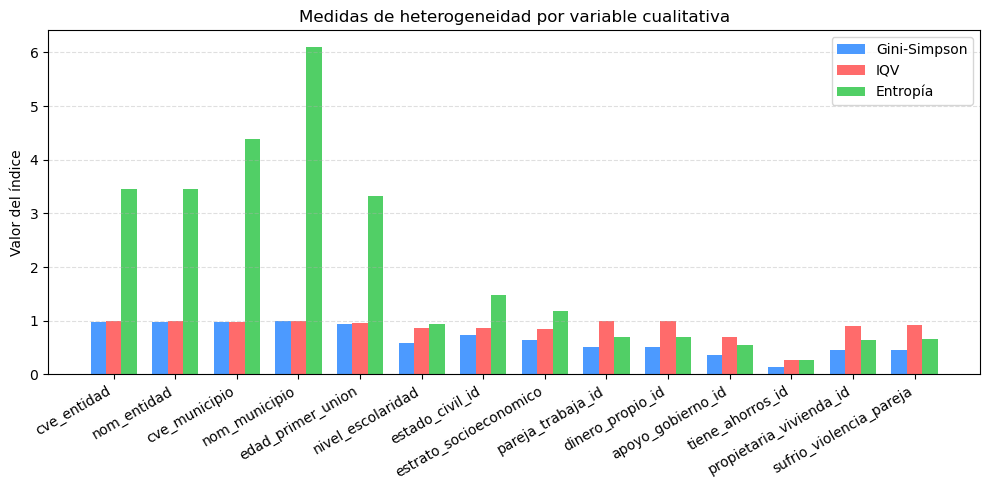

In [9]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(cualitativas))
ancho = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x - ancho, ginis, width=ancho, label="Gini-Simpson", color="#4C9AFF")
ax.bar(x, iqvs, width=ancho, label="IQV", color="#FF6B6B")
ax.bar(x + ancho, entropias, width=ancho, label="Entropía", color="#51CF66")

ax.set_xticks(x)
ax.set_xticklabels(cualitativas, rotation=30, ha="right")
ax.set_ylabel("Valor del índice")
ax.set_title("Medidas de heterogeneidad por variable cualitativa")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()